# Chapitre 2 - Exercices 2.1 à 2.6

Ce notebook propose six exercices corrigés sur la première moitié du chapitre 2
(données, architecture, taille et calcul) :

- **2.1** : le coût d'un assistant multilingue, langue par langue (mesure + calcul) ;
- **2.2** : propriétés de l'attention causale (dépendance au futur, rôle des positions,
  mémoire de la matrice de scores) ;
- **2.3** : nombre de paramètres et mémoire d'un modèle à partir de sa configuration ;
- **2.4** : FLOPs, durée, coût et énergie d'un pré-entraînement, comparés à l'inférence ;
- **2.5** : dimensionner un modèle pour un budget avec la loi de Chinchilla ;
- **2.6** : pourquoi le decode est limité par la mémoire, et comment le batch aide
  (calcul d'intensité arithmétique + mini-lab).

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
import torch
from transformers import AutoTokenizer

from aie import llm
from aie import ch02_modeles as m
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 2)
sci = lambda v: f"{v:.0e}".replace("e+", "e")

## Exercice 2.1 : Le coût d'un assistant multilingue

**Énoncé.** Une entreprise déploie un assistant de support client. Chaque mois, il traite
2 millions de conversations ; une conversation représente, **mesurée en anglais**,
800 tokens d'entrée et 250 tokens de sortie. Le trafic se répartit ainsi : anglais 40 %,
français 25 %, espagnol 15 %, arabe 10 %, hindi 10 %. Le fournisseur facture 2,50 \$ par
million de tokens d'entrée et 10 \$ par million de tokens de sortie.

1. Estimer le coût mensuel si l'on ignorait l'effet de la langue (tout compté comme de
   l'anglais).
2. Mesurer, sur le corpus parallèle du cours, le ratio de tokens de chaque langue par
   rapport à l'anglais pour les tokenizers `cl100k_base` (GPT-4) et `o200k_base` (GPT-4o),
   puis recalculer le coût réel avec chacun.
3. Quelle part du coût provient des utilisateurs hindiphones dans chaque cas ? Qu'en
   conclure sur le choix d'un modèle pour un marché donné ?

**Rappels.** Le coût et la latence sont proportionnels au nombre de tokens (section
*Multilingual Models*). Pour un même contenu, le nombre de tokens dépend de la langue et
du tokenizer : on note $r_\ell$ le ratio de tokens de la langue $\ell$ par rapport à
l'anglais (cours 1, section 3).

**Solution.**

1. Sans effet de langue : entrée $2\cdot 10^6 \times 800 = 1{,}6\cdot 10^9$ tokens, soit
   $1600 \times 2{,}50 = 4000$ \$ ; sortie $2\cdot10^6 \times 250 = 5\cdot 10^8$ tokens, soit
   $500 \times 10 = 5000$ \$. Total : **9 000 \$ par mois**.
2. Avec effet de langue, chaque langue est pondérée par sa part de trafic $s_\ell$ et son
   ratio $r_\ell$ :
   $$\text{coût} = 9000 \times \sum_\ell s_\ell\, r_\ell .$$
   Le facteur $\bar r = \sum_\ell s_\ell r_\ell$ est le **surcoût moyen** dû aux langues.
3. La part de la langue $\ell$ dans le coût vaut $s_\ell r_\ell / \bar r$.

In [2]:
traffic = {"en": 0.40, "fr": 0.25, "es": 0.15, "ar": 0.10, "hi": 0.10}
encs = {name: tiktoken.get_encoding(name).encode for name in ["cl100k_base", "o200k_base"]}
fert = m.tokens_per_language(encs, {k: m.PARALLEL_CORPUS[k] for k in traffic})
base_cost = 2e6 * 800 / 1e6 * 2.5 + 2e6 * 250 / 1e6 * 10
rows = []
for name in encs:
    r = fert[fert.tokenizer == name].set_index("code")["ratio_vs_en"]
    rbar = sum(traffic[l] * r[l] for l in traffic)
    rows.append(dict(tokenizer=name, surcout_moyen=rbar, cout_mensuel=base_cost * rbar,
                     **{f"part {m.LANG_NAMES[l]}": traffic[l] * r[l] / rbar for l in traffic}))
res = pd.DataFrame(rows).set_index("tokenizer")
print(f"coût naïf (tout en anglais) : {base_cost:,.0f} $".replace(",", " "))
res.round(2)

coût naïf (tout en anglais) : 9 000 $


,surcout_moyen,cout_mensuel,part anglais,part français,part espagnol,part arabe,part hindi
tokenizer,,,,,,,
cl100k_base,1.62,14616.35,0.25,0.22,0.12,0.15,0.27
o200k_base,1.08,9709.62,0.37,0.25,0.15,0.10,0.13


**Vérification graphique** : part du trafic et part du coût par langue.

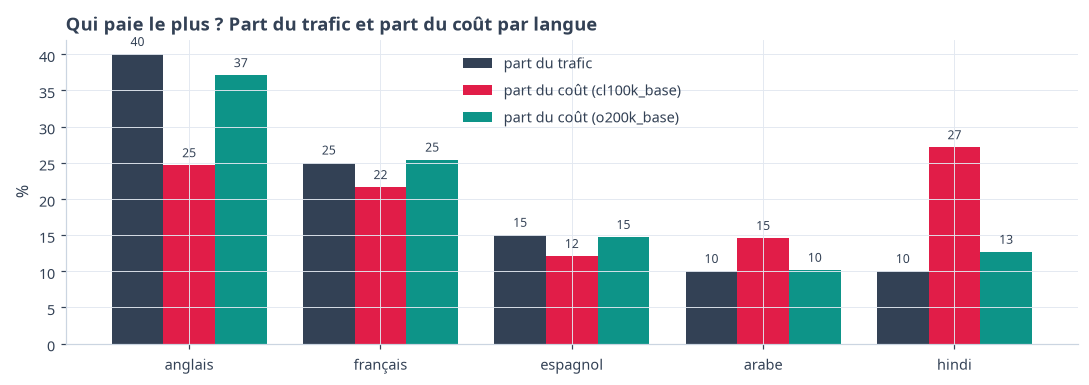

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.6))
langs = [m.LANG_NAMES[l] for l in traffic]
x = np.arange(len(langs))
ax.bar(x - 0.27, [traffic[l] * 100 for l in traffic], 0.27, color=SLATE, label="part du trafic")
for k, (name, c) in enumerate(zip(encs, [ROSE, TEAL])):
    ax.bar(x + k * 0.27, res.loc[name, [f"part {n}" for n in langs]].values * 100, 0.27, color=c,
           label=f"part du coût ({name})")
annotate_bars(ax, "{:.0f}", fontsize=8)
ax.set_xticks(x, langs); ax.set_ylabel("%"); ax.legend()
ax.set_title("Qui paie le plus ? Part du trafic et part du coût par langue")
plt.tight_layout(); plt.show()

Avec `cl100k_base`, les 10 % d'utilisateurs hindiphones pèsent nettement plus que 10 % de
la facture (chaque requête en hindi coûte plusieurs fois une requête en anglais) ; avec
`o200k_base`, dont le vocabulaire couvre mieux le devanagari, l'écart se réduit
fortement. Le choix du modèle (et donc du tokenizer) a ainsi un effet direct sur le coût
par marché, et aussi sur la latence et le contexte utile. Notre corpus est minuscule
(6 phrases) : en pratique, on mesure ces ratios sur un échantillon représentatif du
trafic réel.

> **À retenir.** Le surcoût linguistique moyen vaut $\sum_\ell s_\ell r_\ell$ : il se
> mesure en quelques lignes, et peut justifier à lui seul de changer de modèle pour un
> marché non anglophone.

## Exercice 2.2 : Propriétés de l'attention causale

**Énoncé.** On considère une couche d'attention à une tête, $\text{out} =
\operatorname{softmax}(QK^\top/\sqrt d + M)V$ avec $M_{ij} = -\infty$ si $j > i$, 0 sinon.

1. Montrer que la sortie en position $i$ ne dépend pas des tokens $j > i$, et le vérifier
   numériquement en perturbant les derniers tokens.
2. **Sans** masque ni encodage de position, montrer que permuter les tokens d'entrée
   permute les sorties de la même façon (équivariance). Pourquoi est-ce un problème pour
   un modèle de langue ?
3. Si l'on matérialisait la matrice des scores (sans optimisation), quelle mémoire
   faudrait-il pour Llama 2-7B (32 couches, 32 têtes) en bf16, pour un contexte de 4 096,
   32 768 et 131 072 tokens ?

**Rappels.** Section *Attention mechanism* : $Q = xW_Q$, $K = xW_K$, $V = xW_V$ ; le
masque causal empêche un token de voir le futur (cours 1, section 6). Chaque tête calcule
une matrice de scores $T \times T$.

**Solution.**

1. La ligne $i$ des poids vaut $A_{ij} = e^{s_{ij} + M_{ij}} / \sum_k e^{s_{ik} + M_{ik}}$.
   Pour $j > i$, $e^{-\infty} = 0$ : ces termes disparaissent du numérateur **et** du
   dénominateur. La sortie $\sum_j A_{ij} v_j$ ne fait donc intervenir que $q_i$, et $k_j,
   v_j$ pour $j \le i$, qui ne dépendent que de $x_j$ pour $j \le i$. $\blacksquare$
2. Soit $P$ une matrice de permutation. Sans masque : $Q' = PQ$, $K' = PK$, $V' = PV$, donc
   $Q'K'^\top = P\,QK^\top P^\top$. La softmax ligne par ligne commute avec cette
   double permutation, d'où $\text{out}' = P\,A\,P^\top P V = P\,\text{out}$. $\blacksquare$
   L'attention seule voit donc un **sac de tokens** : « le chien mord l'homme » et
   « l'homme mord le chien » produiraient les mêmes représentations (permutées). D'où les
   encodages de position (appris dans GPT-2, rotatifs avec RoPE). Remarque : le masque
   causal brise lui aussi cette symétrie, ce qui donne une information de position
   implicite.
3. Mémoire : $L \times h \times T^2 \times 2$ octets. Pour $T = 4096$ :
   $32 \times 32 \times 4096^2 \times 2 \approx 34$ Go ; pour $T = 131\,072$, $1024$ fois plus,
   soit environ 35 To. Même une seule couche à la fois (1/32) reste énorme à 128 k tokens :
   d'où les noyaux comme FlashAttention, qui ne matérialisent jamais la matrice entière
   (chapitre 9).

In [4]:
T, dd = 8, 16
x = rng.normal(size=(T, dd))
Wq, Wk, Wv, Wo = rng.normal(0, 1 / np.sqrt(dd), (4, dd, dd))
out1, _ = m.multi_head_attention(x, Wq, Wk, Wv, Wo, n_heads=2, causal=True)
x2 = x.copy(); x2[5:] = rng.normal(size=(3, dd)) * 10          # on bouleverse les 3 derniers tokens
out2, _ = m.multi_head_attention(x2, Wq, Wk, Wv, Wo, n_heads=2, causal=True)
diff_pos = np.abs(out1 - out2).max(1)
perm = rng.permutation(T)
o_nc, _ = m.multi_head_attention(x, Wq, Wk, Wv, Wo, n_heads=2, causal=False)
o_perm, _ = m.multi_head_attention(x[perm], Wq, Wk, Wv, Wo, n_heads=2, causal=False)
print("1) écart de sortie par position après perturbation des tokens 5 à 7 :", np.round(diff_pos, 6))
print(f"2) sans masque : out(x permuté) == out(x) permuté ? {np.allclose(o_perm, o_nc[perm])}")
o_c_perm, _ = m.multi_head_attention(x[perm], Wq, Wk, Wv, Wo, n_heads=2, causal=True)
print(f"   avec masque causal : même test ? {np.allclose(o_c_perm, out1[perm])}")

1) écart de sortie par position après perturbation des tokens 5 à 7 : [ 0.        0.        0.        0.        0.       19.073849 20.059821
 18.264297]
2) sans masque : out(x permuté) == out(x) permuté ? True
   avec masque causal : même test ? False


**Vérification graphique** de la question 3.

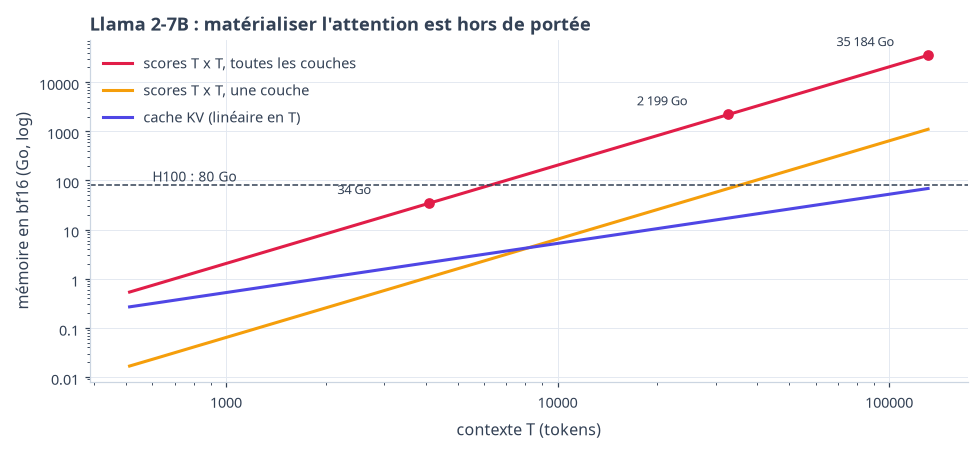

In [5]:
cfg = m.KNOWN_CONFIGS["Llama 2-7B"]
Tg = np.logspace(np.log10(512), np.log10(131072), 60)
mem_all = [m.attention_matrix_bytes(int(t), cfg.n_heads, cfg.n_layers) / 1e9 for t in Tg]
mem_one = [m.attention_matrix_bytes(int(t), cfg.n_heads, 1) / 1e9 for t in Tg]
kv = [m.kv_cache_bytes(cfg, int(t)) / 1e9 for t in Tg]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(Tg, mem_all, color=ROSE, label="scores T x T, toutes les couches")
ax.loglog(Tg, mem_one, color=AMBER, label="scores T x T, une couche")
ax.loglog(Tg, kv, color=INDIGO, label="cache KV (linéaire en T)")
ax.axhline(80, color=SLATE, ls="--", lw=1); ax.text(600, 95, "H100 : 80 Go", fontsize=9)
for t in [4096, 32768, 131072]:
    v = m.attention_matrix_bytes(t, cfg.n_heads, cfg.n_layers) / 1e9
    ax.plot(t, v, "o", color=ROSE); ax.annotate(f"{v:,.0f} Go".replace(",", " "), (t, v), xytext=(-60, 6),
                                                 textcoords="offset points", fontsize=8.5)
ax.set_xlabel("contexte T (tokens)"); ax.set_ylabel("mémoire en bf16 (Go, log)")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y")
ax.set_title("Llama 2-7B : matérialiser l'attention est hors de portée"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

> **À retenir.** Le masque causal garantit qu'un token ne voit que son passé ; sans
> positions, l'attention est aveugle à l'ordre ; et la matrice de scores croît en $T^2$, ce
> qui interdit de la matérialiser pour les longs contextes.

## Exercice 2.3 : Paramètres et mémoire à partir de la configuration

**Énoncé.** La configuration publique de Mistral-7B est : $d = 4096$, $L = 32$,
$d_{ff} = 14\,336$ (MLP SwiGLU), $V = 32\,000$, $h = 32$ têtes de requêtes, $h_{kv} = 8$
têtes clés-valeurs (GQA), plongements **non** partagés, RMSNorm sans biais.

1. Calculer à la main le nombre de paramètres, composant par composant.
2. En déduire la mémoire des poids en bf16 et en int4, puis la taille du cache KV pour
   une conversation de 32 768 tokens en bf16.
3. Combien de conversations simultanées de 8 192 tokens peut-on servir sur un GPU de
   80 Go avec les poids en bf16 ? Et sans GQA ($h_{kv} = 32$) ?
4. Vérifier avec `m.count_params_config` et `m.kv_cache_bytes`.

**Rappels.** Cours 2, sections 1 et 2 : attention $d^2 + 2d\,h_{kv}d_h + d^2$ par bloc,
MLP SwiGLU $3d\,d_{ff}$, plongements et sortie $Vd$ chacun, normalisations $2d$ par bloc
plus $d$ ; cache KV $2Lh_{kv}d_hTb$ (section *Model Size*).

**Solution.**

1. $d_h = 4096/32 = 128$, et $h_{kv} d_h = 1024$.
   - Attention par bloc : $4096^2 + 2 \times 4096 \times 1024 + 4096^2 = 16{,}78 + 8{,}39 +
     16{,}78 = 41{,}94$ M.
   - MLP par bloc : $3 \times 4096 \times 14\,336 = 176{,}16$ M.
   - Normalisations par bloc : $2 \times 4096 = 8192$.
   - Total des 32 blocs : $32 \times 218{,}11 \text{ M} = 6{,}98$ G.
   - Plongements + sortie : $2 \times 32\,000 \times 4096 = 262{,}1$ M ; norme finale : 4096.
   - **Total : environ 7,24 milliards** de paramètres.
2. Poids : $7{,}24\cdot10^9 \times 2 \approx 14{,}5$ Go en bf16, $\approx 3{,}6$ Go en int4.
   Cache KV à 32 768 tokens : $2 \times 32 \times 8 \times 128 \times 32\,768 \times 2 =
   4{,}29\cdot10^9$ octets, soit 4 Gio.
3. Mémoire libre : $80 - 14{,}5 = 65{,}5$ Go (on néglige activations et fragmentation).
   Une conversation de 8 192 tokens occupe 1 Gio $\approx 1{,}07$ Go avec GQA, d'où environ
   **61 conversations** ; sans GQA, le cache est 4 fois plus gros (4,3 Go), d'où environ
   **15 conversations**. La GQA quadruple ici la capacité de service.

In [6]:
mistral = m.TransformerConfig("Mistral-7B", 4096, 32, 14336, 32000, 32, 8, context=32768)
mistral_mha = m.TransformerConfig("Mistral-7B sans GQA", 4096, 32, 14336, 32000, 32, 32, context=32768)
N = m.count_params_config(mistral)
print("répartition :", {k: f"{v / 1e6:.1f} M" for k, v in m.param_breakdown(mistral).items() if v})
print(f"total : {N:,} paramètres".replace(",", " "))
print(f"poids bf16 : {m.weights_memory_gb(N, 2):.1f} Go ; int4 : {m.weights_memory_gb(N, 0.5):.1f} Go")
print(f"cache KV 32k tokens : {m.kv_cache_bytes(mistral, 32768) / 2**30:.2f} Gio")
free = 80e9 - N * 2
for c in [mistral, mistral_mha]:
    print(f"{c.name} : {int(free // m.kv_cache_bytes(c, 8192))} conversations de 8 192 tokens")

répartition : {'embeddings': '131.1 M', 'attention': '1342.2 M', 'mlp': '5637.1 M', 'normalisations': '0.3 M', 'tête de sortie': '131.1 M'}
total : 7 241 732 096 paramètres
poids bf16 : 14.5 Go ; int4 : 3.6 Go
cache KV 32k tokens : 4.00 Gio
Mistral-7B : 61 conversations de 8 192 tokens
Mistral-7B sans GQA : 15 conversations de 8 192 tokens


**Vérification graphique** : nombre de conversations servies en fonction de leur longueur.

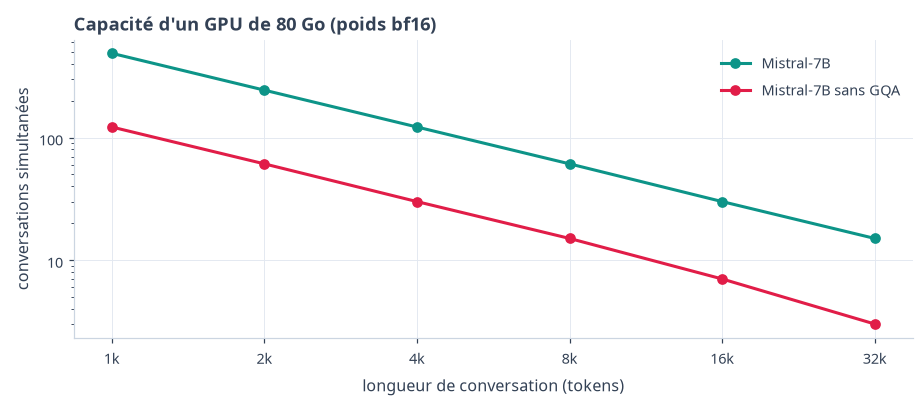

In [7]:
lens = np.array([1024, 2048, 4096, 8192, 16384, 32768])
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for c, col in [(mistral, TEAL), (mistral_mha, ROSE)]:
    ax.plot(lens, [free // m.kv_cache_bytes(c, int(t)) for t in lens], "o-", color=col, label=c.name)
ax.set_xscale("log", base=2); ax.set_xticks(lens, [f"{t // 1024}k" for t in lens])
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_xlabel("longueur de conversation (tokens)"); ax.set_ylabel("conversations simultanées")
ax.set_title("Capacité d'un GPU de 80 Go (poids bf16)"); ax.legend()
plt.tight_layout(); plt.show()

> **À retenir.** Avec la configuration, on calcule en quelques lignes paramètres, mémoire
> des poids et cache KV, et donc la capacité de service. La GQA divise le cache par
> $h/h_{kv}$.